<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Yolo_%2B_SAHI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q -U ultralytics sahi

In [21]:
import torch, cv2, os
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

device = "cuda:0" if torch.cuda.is_available() else "cpu"

# Descarga los pesos si no existen (n, s, m, l, x)
MODELO = "yolo26n.pt"
YOLO(MODELO)

detection_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=MODELO,
    confidence_threshold=0.4,
    device=device,
)
print("Modelo listo en:", device)

Modelo listo en: cpu


Performing prediction on 2 slices.
Detecciones: 15


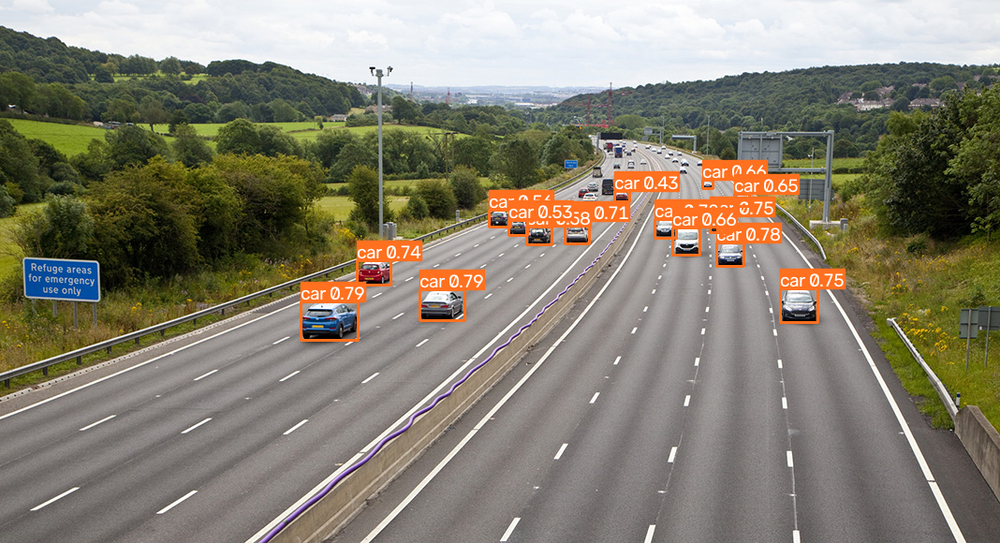

In [24]:
from google.colab import files
from IPython.display import Image, display

# Opción A: imagen de ejemplo (objetos pequeños)
!wget -q https://raw.githubusercontent.com/obss/sahi/main/demo/demo_data/small-vehicles1.jpeg -O imagen.jpg
ruta_img = "imagen.jpg"

# Opción B: subir la tuya (descomenta)
# ruta_img = list(files.upload().keys())[0]

resultado = get_sliced_prediction(
    ruta_img,
    detection_model,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
)

resultado.export_visuals(export_dir="salida_img/", file_name="sahi")
print("Detecciones:", len(resultado.object_prediction_list))
display(Image("salida_img/sahi.png"))


image 1/1 /content/imagen.jpg: 352x640 19 cars, 1 truck, 174.7ms
Speed: 1.5ms preprocess, 174.7ms inference, 0.7ms postprocess per image at shape (1, 3, 352, 640)


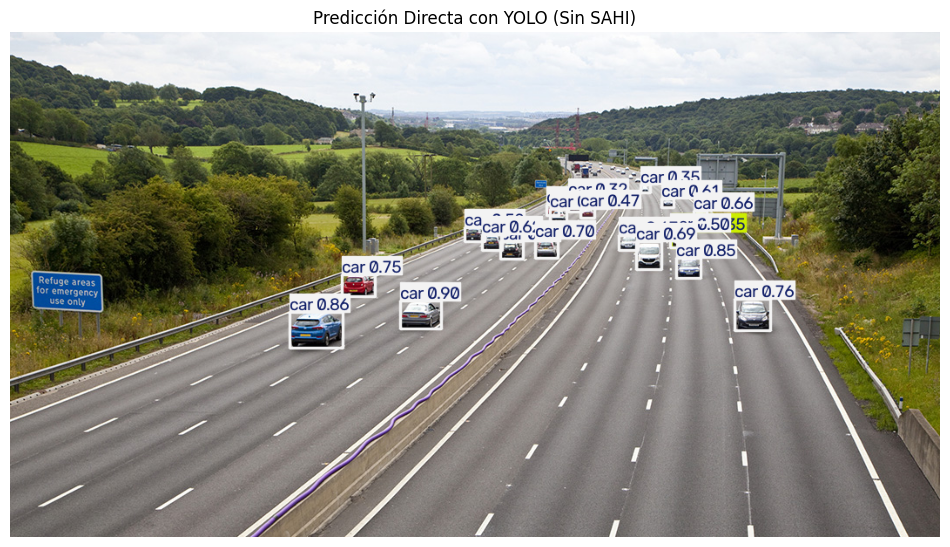

Detecciones encontradas por YOLO directo: 20


In [11]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Cargar el modelo YOLO directamente
modelo_yolo = YOLO(MODELO)

# 2. Realizar la predicción estándar (sin SAHI)
resultados = modelo_yolo(ruta_img)

# 3. Obtener la imagen con los resultados dibujados
imagen_pred = resultados[0].plot()

# 4. Convertir de BGR (formato de OpenCV) a RGB para mostrar con matplotlib
imagen_pred_rgb = cv2.cvtColor(imagen_pred, cv2.COLOR_BGR2RGB)

# 5. Mostrar la imagen
plt.figure(figsize=(12, 8))
plt.imshow(imagen_pred_rgb)
plt.title("Predicción Directa con YOLO (Sin SAHI)")
plt.axis("off")
plt.show()

# Imprimir cantidad de detecciones encontradas
cantidad_detecciones = len(resultados[0].boxes)
print(f"Detecciones encontradas por YOLO directo: {cantidad_detecciones}")

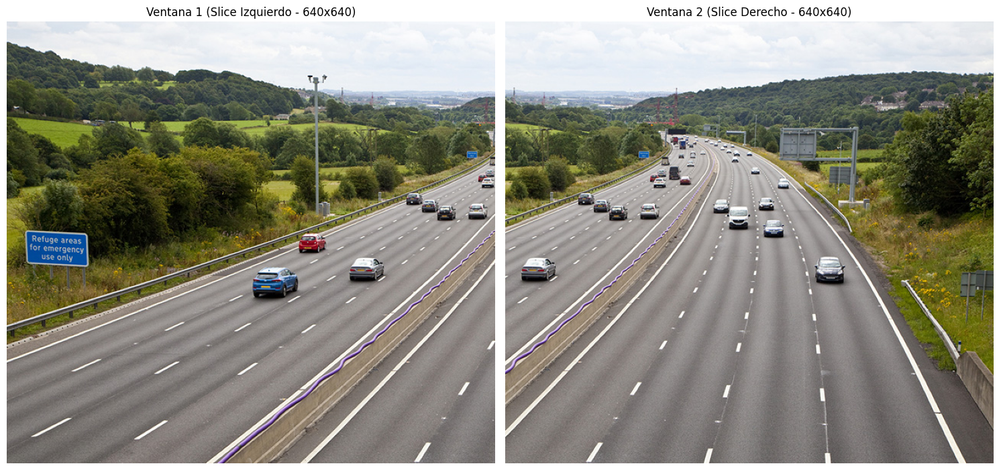

In [25]:
import matplotlib.pyplot as plt

# Obtenemos las dimensiones de la imagen original
imagen_original = cv2.imread(ruta_img)
imagen_original = cv2.cvtColor(imagen_original, cv2.COLOR_BGR2RGB)

# SAHI guarda las posiciones y las detecciones de cada ventana procesada
# Podemos recrear o visualizar los cortes usando las posiciones de los slices
slices_posiciones = resultado.durations_in_seconds  # Información de ejecución

# Para mostrar las ventanas y sus detecciones de forma clara, podemos iterar
# sobre las detecciones o bien visualizar directamente los dos slices generados:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# El primer slice cubre la parte izquierda y el segundo la parte derecha de la imagen
# (ya que tiene un ancho original y el tamaño del slice es de 640x640 con 20% de solapamiento)
slice_1 = imagen_original[0:640, 0:640]
# Con overlap de 20% (128 px), el segundo slice empieza en X = 640 - 128 = 512 (o según las dimensiones de la imagen)
# Vamos a recortar ambas regiones directamente para visualizarlas de manera sencilla:
ancho_original = imagen_original.shape[1]

# Slice 1 (Izquierdo)
axes[0].imshow(slice_1)
axes[0].set_title("Ventana 1 (Slice Izquierdo - 640x640)")
axes[0].axis('off')

# Slice 2 (Derecho)
start_x = max(0, ancho_original - 640)
slice_2 = imagen_original[0:640, start_x:ancho_original]
axes[1].imshow(slice_2)
axes[1].set_title("Ventana 2 (Slice Derecho - 640x640)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

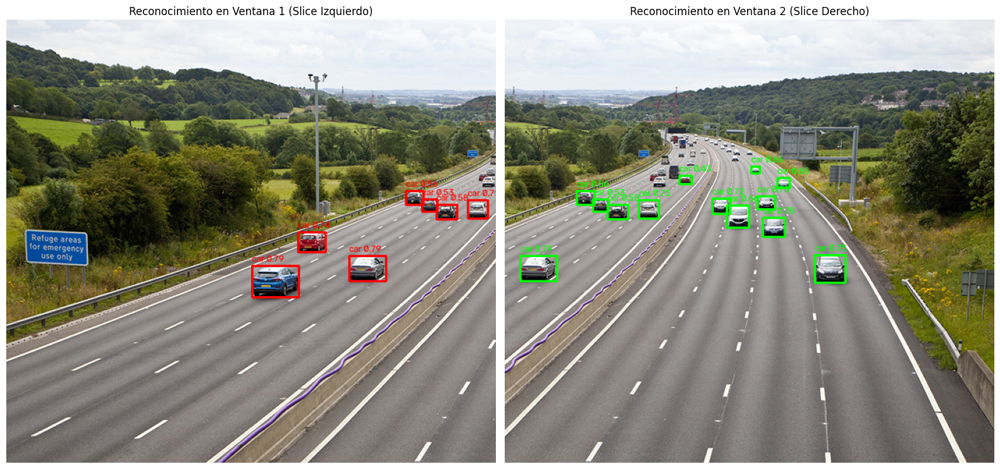

In [26]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Volvemos a leer la imagen original limpia
img_visual = cv2.imread(ruta_img)
img_visual = cv2.cvtColor(img_visual, cv2.COLOR_BGR2RGB)

# Creamos copias de los dos recortes de ventana (slices) para dibujar en ellas por separado
# Slice 1: X de [0 a 640]
slice_1_det = img_visual[0:640, 0:640].copy()

# Slice 2: X de [start_x a ancho_original]
ancho_original = img_visual.shape[1]
start_x = max(0, ancho_original - 640)
slice_2_det = img_visual[0:640, start_x:ancho_original].copy()

# Iteramos sobre todas las detecciones individuales para ver en qué ventana caen
for p in resultado.object_prediction_list:
    x1, y1, x2, y2 = map(int, p.bbox.to_xyxy())
    nombre = p.category.name
    score = p.score.value
    etiqueta = f"{nombre} {score:.2f}"

    # Si la predicción está en la Ventana 1 (X totalmente dentro de 0 y 640)
    if x2 <= 640:
        # Coordenadas locales al primer slice
        cv2.rectangle(slice_1_det, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(slice_1_det, etiqueta, (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1, cv2.LINE_AA)

    # Si la predicción está en la Ventana 2 (X empieza después del inicio de la Ventana 2)
    if x1 >= start_x:
        # Coordenadas locales al segundo slice (restamos start_x en el eje X)
        lx1, lx2 = x1 - start_x, x2 - start_x
        cv2.rectangle(slice_2_det, (lx1, y1), (lx2, y2), (0, 255, 0), 2)
        cv2.putText(slice_2_det, etiqueta, (lx1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1, cv2.LINE_AA)

# Mostramos las dos ventanas con sus detecciones correspondientes
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(slice_1_det)
axes[0].set_title("Reconocimiento en Ventana 1 (Slice Izquierdo)")
axes[0].axis('off')

axes[1].imshow(slice_2_det)
axes[1].set_title("Reconocimiento en Ventana 2 (Slice Derecho)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

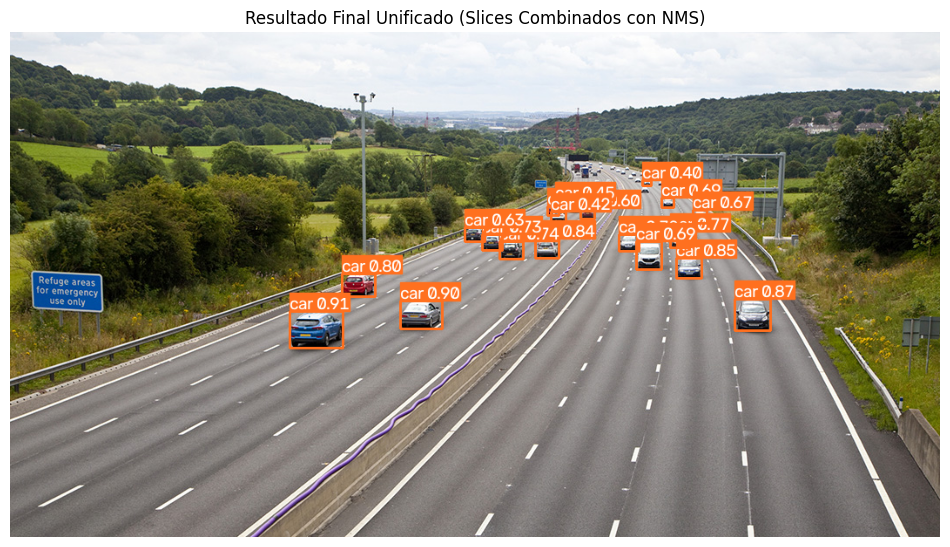

In [14]:
import cv2
import matplotlib.pyplot as plt

# Exportamos la visualización final unificada que genera SAHI automáticamente
resultado.export_visuals(export_dir="salida_img/", file_name="sahi_final")

# Cargamos y mostramos la imagen final combinada con matplotlib
imagen_final = cv2.imread("salida_img/sahi_final.png")
imagen_final = cv2.cvtColor(imagen_final, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(imagen_final)
plt.title("Resultado Final Unificado (Slices Combinados con NMS)")
plt.axis("off")
plt.show()


image 1/1 /content/imagen_dificil.jpg: 352x640 11 cars, 56.9ms
Speed: 1.7ms preprocess, 56.9ms inference, 0.7ms postprocess per image at shape (1, 3, 352, 640)


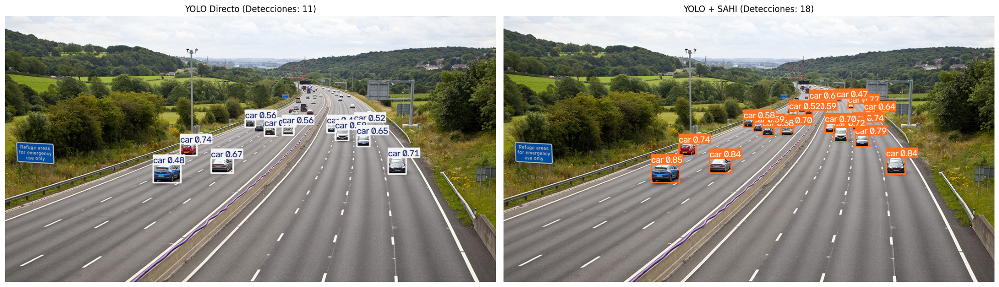

Resultado final:
- Con YOLO directo se detectaron: 11 objetos.
- Con YOLO + SAHI se detectaron: 18 objetos.


In [23]:
import cv2
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO
from sahi.predict import get_sliced_prediction

# 1. Descargar otra imagen aérea de carreteras/tráfico con objetos muy pequeños
url_imagen_nueva = "https://raw.githubusercontent.com/obss/sahi/main/demo/demo_data/small-vehicles1.jpeg"
!curl -L -s "{url_imagen_nueva}" -o imagen_dificil.jpg
ruta_img_dificil = "imagen_dificil.jpg"

# Verificar que el archivo realmente existe y no está vacío
if not os.path.exists(ruta_img_dificil) or os.path.getsize(ruta_img_dificil) == 0:
    raise FileNotFoundError("No se pudo descargar la nueva imagen correctamente. Intente de nuevo.")

# 2. Predicción Directa con YOLO
modelo_yolo = YOLO(MODELO)
resultados_directo = modelo_yolo(ruta_img_dificil, conf=0.25)

# Obtener visualizaciones de YOLO
imagen_directo = resultados_directo[0].plot()
imagen_directo_rgb = cv2.cvtColor(imagen_directo, cv2.COLOR_BGR2RGB)
cantidad_directo = len(resultados_directo[0].boxes)

# 3. Predicción utilizando SAHI
resultado_sahi = get_sliced_prediction(
    ruta_img_dificil,
    detection_model,
    slice_height=400,
    slice_width=400,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    verbose=0
)

resultado_sahi.export_visuals(export_dir="salida_img/", file_name="sahi_dificil")
imagen_sahi = cv2.imread("salida_img/sahi_dificil.png")
imagen_sahi_rgb = cv2.cvtColor(imagen_sahi, cv2.COLOR_BGR2RGB)
cantidad_sahi = len(resultado_sahi.object_prediction_list)

# 4. Mostrar y comparar ambos resultados lado a lado
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

axes[0].imshow(imagen_directo_rgb)
axes[0].set_title(f"YOLO Directo (Detecciones: {cantidad_directo})")
axes[0].axis("off")

axes[1].imshow(imagen_sahi_rgb)
axes[1].set_title(f"YOLO + SAHI (Detecciones: {cantidad_sahi})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Resultado final:")
print(f"- Con YOLO directo se detectaron: {cantidad_directo} objetos.")
print(f"- Con YOLO + SAHI se detectaron: {cantidad_sahi} objetos.")

In [ ]:
import numpy as np
from collections import Counter

def procesar_video(entrada, salida="salida_sahi.mp4",
                   slice_size=640, overlap=0.2, saltar_frames=0, max_frames=None):
    cap = cv2.VideoCapture(entrada)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    out = cv2.VideoWriter("tmp.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    rng = np.random.default_rng(42)
    colores = {}
    n = 0
    ultimo = []

    while cap.isOpened():
        ok, frame = cap.read()
        if not ok or (max_frames and n >= max_frames):
            break

        # Con saltar_frames=2 procesa 1 de cada 3 frames y reutiliza las cajas (más rápido)
        if n % (saltar_frames + 1) == 0:
            res = get_sliced_prediction(
                frame[:, :, ::-1],  # BGR -> RGB
                detection_model,
                slice_height=slice_size,
                slice_width=slice_size,
                overlap_height_ratio=overlap,
                overlap_width_ratio=overlap,
                verbose=0,
            )
            ultimo = res.object_prediction_list

        for p in ultimo:
            x1, y1, x2, y2 = map(int, p.bbox.to_xyxy())
            nombre = p.category.name
            if nombre not in colores:
                colores[nombre] = tuple(int(c) for c in rng.integers(60, 255, 3))
            c = colores[nombre]
            cv2.rectangle(frame, (x1, y1), (x2, y2), c, 2)
            etiqueta = f"{nombre} {p.score.value:.2f}"
            cv2.putText(frame, etiqueta, (x1, max(y1 - 5, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1, cv2.LINE_AA)

        cv2.putText(frame, f"Objetos: {len(ultimo)}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)
        out.write(frame)
        n += 1

    cap.release(); out.release()
    # Re-codificar a H.264 para que se reproduzca en el navegador
    os.system(f"ffmpeg -y -loglevel error -i tmp.mp4 -vcodec libx264 -pix_fmt yuv420p {salida}")
    print(f"Listo: {n} frames -> {salida}")

# Subir tu video
ruta_video = list(files.upload().keys())[0]
procesar_video(ruta_video, saltar_frames=1, max_frames=300)

Saving 854671-hd_1920_1080_25fps.mp4 to 854671-hd_1920_1080_25fps.mp4
Listo: 300 frames -> salida_sahi.mp4


In [ ]:
from IPython.display import HTML
from base64 import b64encode

data = b64encode(open("salida_sahi.mp4", "rb").read()).decode()
display(HTML(f'<video width=700 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

files.download("salida_sahi.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>